# Job Salary Analysis

## 1. Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

## 2. Load Dataset

In [2]:
salary_df = pd.read_csv("data/salaries.csv")
salary_df.head()

,work_year,experience_level,employment_type,job_title,salary,salary_currency,salary_in_usd,employee_residence,remote_ratio,company_location,company_size
0,2025,EN,FT,Data Analist,65664,EUR,69120,NL,0,NL,M
1,2025,EN,FT,Data Analist,47652,EUR,50160,NL,0,NL,M
2,2025,EN,FT,Data Engineer,158113,USD,158113,US,0,US,M
3,2025,EN,FT,Data Engineer,87795,USD,87795,US,0,US,M
4,2025,EX,FT,Data Engineer,351410,USD,351410,US,0,US,M


## 3. Initial Data Exploration

### 3.1 Dataset Dimension

In [3]:
salary_df.shape

(105434, 11)

### 3.2 Data Types

In [4]:
salary_df.dtypes

work_year             int64
experience_level        str
employment_type         str
job_title               str
salary                int64
salary_currency         str
salary_in_usd         int64
employee_residence      str
remote_ratio          int64
company_location        str
company_size            str
dtype: object

### 3.3 Numerical Summary

In [5]:
salary_df.describe().T

,count,mean,std,min,25%,50%,75%,max
work_year,105434.0,2024.188981,0.669665,2020.0,2024.0,2024.0,2025.0,2025.0
salary,105434.0,162690.778117,213723.596787,14000.0,106400.0,147100.0,199700.0,30400000.0
salary_in_usd,105434.0,158018.514179,74401.714026,15000.0,106400.0,147000.0,199000.0,800000.0
remote_ratio,105434.0,21.103249,40.714744,0.0,0.0,0.0,0.0,100.0


### 3.4 Missing Values

In [6]:
salary_df.isnull().sum()

work_year             0
experience_level      0
employment_type       0
job_title             0
salary                0
salary_currency       0
salary_in_usd         0
employee_residence    0
remote_ratio          0
company_location      0
company_size          0
dtype: int64

### 3.5 Duplicate Record

In [7]:
salary_df.duplicated().sum()

np.int64(52997)

### 3.6 Unique Value

In [8]:
for title in sorted(salary_df['job_title'].unique()):
    print(title)

AI Architect
AI Data Engineer
AI Data Scientist
AI Developer
AI Engineer
AI Engineering Manager
AI Governance Lead
AI Lead
AI Machine Learning Engineer
AI Product Lead
AI Product Manager
AI Product Owner
AI Programmer
AI Research Engineer
AI Research Scientist
AI Researcher
AI Scientist
AI Software Development Engineer
AI Software Engineer
AI Solution Architect
AI Specialist
AI Tech Lead
AWS Data Architect
Account Executive
Actuarial Analyst
Admin & Data Analyst
Algorithm Developer
Alternance
Analyst
Analytics Analyst
Analytics Engineer
Analytics Engineering Manager
Analytics Lead
Analytics Specialist
Application Developer
Applied AI ML Lead
Applied Data Scientist
Applied Machine Learning Engineer
Applied Machine Learning Scientist
Applied Research Scientist
Applied Scientist
Architect
Artificial Intelligence Engineer
Associate
Autonomous Vehicle Technician
Azure Data Engineer
BI Analyst
BI Data Analyst
BI Data Engineer
BI Developer
BI Engineer
Backend Developer
Backend Engineer
Backen

In [9]:
salary_df['experience_level'].unique()

<StringArray>
['EN', 'EX', 'SE', 'MI']
Length: 4, dtype: str

In [10]:
salary_df['employment_type'].unique()

<StringArray>
['FT', 'PT', 'CT', 'FL']
Length: 4, dtype: str

In [11]:
salary_df['remote_ratio'].unique()

array([  0, 100,  50])

# 4. Data Cleaning

## 4.1 Handle Duplicate Valuese

In [12]:
duplicate_rows = salary_df[
    salary_df.duplicated(keep=False)
]

duplicate_rows.head(10)

,work_year,experience_level,employment_type,job_title,salary,salary_currency,salary_in_usd,employee_residence,remote_ratio,company_location,company_size
9,2025,SE,FT,Systems Engineer,160000,USD,160000,US,100,US,M
24,2025,SE,FT,Machine Learning Engineer,230000,USD,230000,US,0,US,M
25,2025,SE,FT,Machine Learning Engineer,175000,USD,175000,US,0,US,M
34,2025,MI,FT,Business Intelligence Developer,107309,USD,107309,CA,0,CA,M
35,2025,MI,FT,Business Intelligence Developer,85839,USD,85839,CA,0,CA,M
36,2025,SE,FT,Product Manager,142000,USD,142000,CA,100,CA,M
37,2025,SE,FT,Product Manager,113000,USD,113000,CA,100,CA,M
40,2025,SE,FT,Data Scientist,335720,USD,335720,US,100,US,M
41,2025,SE,FT,Data Scientist,163064,USD,163064,US,100,US,M
42,2025,EN,FT,Data Scientist,77000,USD,77000,US,0,US,M


In [13]:
duplicate_frequency = (
    salary_df
    .value_counts()
    .reset_index(name='frequency')
    .sort_values('frequency', ascending=False)
)

duplicate_frequency.head(10)

,work_year,experience_level,employment_type,job_title,salary,salary_currency,salary_in_usd,employee_residence,remote_ratio,company_location,company_size,frequency
0,2025,SE,FT,Data Scientist,160000,USD,160000,US,100,US,M,188
1,2024,SE,FT,Data Scientist,160000,USD,160000,US,100,US,M,182
2,2025,SE,FT,Data Scientist,110000,USD,110000,US,100,US,M,181
3,2024,SE,FT,Data Scientist,110000,USD,110000,US,100,US,M,168
4,2024,SE,FT,Machine Learning Researcher,160000,USD,160000,US,100,US,M,161
5,2024,SE,FT,Machine Learning Researcher,110000,USD,110000,US,100,US,M,161
6,2024,MI,FT,Applied Scientist,136000,USD,136000,US,0,US,L,113
7,2024,MI,FT,Applied Scientist,222200,USD,222200,US,0,US,L,112
8,2024,SE,FT,Applied Scientist,160000,USD,160000,US,100,US,M,108
9,2024,SE,FT,Applied Scientist,110000,USD,110000,US,100,US,M,107


In [14]:
salary_df = salary_df.drop_duplicates().reset_index(drop=True)

In [15]:
print("Dataset shape:", salary_df.shape)
print("Remaining duplicates:", salary_df.duplicated().sum())

Dataset shape: (52437, 11)
Remaining duplicates: 0


In [16]:
cleaned_df = salary_df.copy()

## 4.2 Categories Unique Value in job_title

In [17]:
number_of_unique_job = cleaned_df['job_title'].nunique()
print("Number of unique job =", number_of_unique_job)

cleaned_df['job_title'].value_counts().head(40)

Number of unique job = 347


job_title
Data Scientist                     5821
Data Engineer                      5623
Data Analyst                       5008
Software Engineer                  3630
Engineer                           3128
Machine Learning Engineer          2916
Manager                            2546
Analyst                            1741
Research Scientist                 1141
Analytics Engineer                 1037
Data Architect                      982
Product Manager                     941
Associate                           890
AI Engineer                         714
Research Engineer                   709
Data Manager                        545
Consultant                          507
Data Specialist                     472
Applied Scientist                   467
Business Intelligence Analyst       446
Software Developer                  394
Engineering Manager                 389
Systems Engineer                    386
Developer                           380
Software Development Engineer 

In [18]:

title_mapping = {

    # Data Engineering
    'Data Modeler': 'Data Engineering',
    'Data Integrator': 'Data Engineering',
    'Cloud Database Administrator': 'Data Engineering',
    'Database Administrator': 'Data Engineering',
    'Elasticsearch Administrator': 'Data Engineering',

    # Data Operations
    'Data Operations': 'Data Operations',
    'Data Operations Specialist': 'Data Operations',
    'Data Operations Associate': 'Data Operations',
    'Data Operations Lead': 'Data Operations',

    # Data Analytics
    'Data Operations Analyst': 'Data Analytics',
    'Actuarial Analyst': 'Research & Science',
    'Pricing Analyst': 'Data Analytics',
    'Lead Analyst': 'Data Analytics',

    # Business Intelligence
    'Data Visualization Specialist': 'Business Intelligence',
    'Data Visualization Analyst': 'Business Intelligence',
    'Data Visualization Designer': 'Business Intelligence',
    'Data Visualization Expert': 'Business Intelligence',
    'Data Reporting Specialist': 'Business Intelligence',
    'Data Reporter': 'Business Intelligence',
    'Data and Reporting Professional': 'Business Intelligence',

    # Research
    'Bioinformatician': 'Research & Science',
    'Computational Scientist': 'Research & Science',

    # Data Strategy
    'Data Strategist': 'Data Strategy & Management',
    'Data Strategy Lead': 'Data Strategy & Management',

    # Management
    'Data Team Lead': 'Management & Leadership',

}


In [19]:
def categorize_job(title):

    title = title.lower()

    if 'machine learning' in title or 'artificial intelligence' in title or 'ai ' in title:
        return 'AI & Machine Learning'

    elif 'data scientist' in title or 'applied scientist' in title:
        return 'Data Science'

    elif 'data engineer' in title or 'data architect' in title or 'database' in title:
        return 'Data Engineering'

    elif 'data governance' in title or 'data steward' in title:
        return 'Data Governance & Management'

    elif 'data operations' in title:
        return 'Data Operations'

    elif 'data strategy' in title:
        return 'Data Strategy & Management'

    elif 'business intelligence' in title or 'data visualization' in title or 'data reporting' in title:
        return 'Business Intelligence'

    elif 'analyst' in title or 'analytics' in title or 'data analysis' in title:
        return 'Data Analytics'

    elif 'software' in title or 'developer' in title:
        return 'Software Engineering'

    elif 'engineer' in title or 'engineering' in title:
        return 'Other Engineering'

    elif 'manager' in title or 'director' in title or 'head of' in title:
        return 'Management & Leadership'

    elif 'research scientist' in title or 'researcher' in title or 'bioinformatician' in title:
        return 'Research & Science'

    elif 'business' in title or 'product' in title or 'consultant' in title:
        return 'Business & Product'

    else:
        return 'Other / Unclassified'

In [20]:
cleaned_df['job_category'] = cleaned_df['job_title'].apply(categorize_job)

mapped_categories = cleaned_df['job_title'].map(title_mapping)

cleaned_df['job_category'] = (
    mapped_categories.fillna(cleaned_df['job_category'])
)

In [21]:
cleaned_df['job_category'].value_counts()

job_category
Data Analytics                  9729
Other Engineering               6889
Data Engineering                6819
Data Science                    6332
Software Engineering            5402
AI & Machine Learning           4866
Management & Leadership         4475
Other / Unclassified            3578
Business Intelligence           1608
Research & Science              1284
Business & Product               731
Data Governance & Management     471
Data Operations                  172
Data Strategy & Management        81
Name: count, dtype: int64

In [22]:
unclassified_titles = (
    cleaned_df.loc[
        cleaned_df['job_category'] == 'Other / Unclassified'
    ]['job_title'].value_counts()
)

unclassified_titles.head(50)

job_title
Associate                                 890
Data Specialist                           472
Solutions Architect                       288
Architect                                 278
Solution Architect                        154
Data Lead                                 150
Data Management Specialist                135
Research Associate                        131
Decision Scientist                        116
Technical Lead                            115
Statistical Programmer                     74
Research Assistant                         61
Statistician                               61
Member of Technical Staff                  54
Data Integration Specialist                52
Bioinformatics Scientist                   43
Computational Biologist                    38
Data Management Lead                       38
Data Quality Lead                          29
Encounter Data Management Professional     28
Enterprise Account Executive               24
Technical Writer        

In [23]:
category_summary = (
    cleaned_df['job_category']
    .value_counts()
    .to_frame(name='records')
)

category_summary['percentage'] = (
    category_summary['records'] /
    len(cleaned_df) * 100
).round(2)

category_summary

,records,percentage
job_category,,
Data Analytics,9729,18.55
Other Engineering,6889,13.14
Data Engineering,6819,13.00
Data Science,6332,12.08
Software Engineering,5402,10.30
AI & Machine Learning,4866,9.28
Management & Leadership,4475,8.53
Other / Unclassified,3578,6.82
Business Intelligence,1608,3.07


## 

## 4.3 Standardize Experience Levels

In [24]:
experience_mapping = {
    'EN': 'Entry-level',
    'MI': 'Mid-level',
    'SE': 'Senior-level',
    'EX': 'Executive'
}

cleaned_df['experience_level'] = (
    cleaned_df['experience_level'].replace(experience_mapping)
    )

cleaned_df['experience_level'].value_counts()

experience_level
Senior-level    27729
Mid-level       16956
Entry-level      6060
Executive        1692
Name: count, dtype: int64

## 4.4 Standardize Employment Types

In [25]:
employment_level_mapping = {
    'FT': 'Full-Time',
    'PT': 'Part-Time',
    'CT': 'Contract',
    'FL': 'Freelance'
}

cleaned_df['employment_type'] = (
    cleaned_df['employment_type'].replace(employment_level_mapping)
)

cleaned_df['employment_type'].value_counts()

employment_type
Full-Time    51931
Part-Time      247
Contract       243
Freelance       16
Name: count, dtype: int64

## 4.5 Standardize Remote Ratio

In [26]:
remote_ratio_mapping = {
    0:   'Fully On-site',
    50:  'Hybrid',
    100: 'Fully Remote'
}

cleaned_df['remote_ratio'] = (
    cleaned_df['remote_ratio'].replace(remote_ratio_mapping)
)

cleaned_df['remote_ratio'].value_counts()

remote_ratio
Fully On-site    39310
Fully Remote     12821
Hybrid             306
Name: count, dtype: int64

## 4.6 Validate the Salary_in_usd Column

### 4.6.1 Compute the implied exchange rate

In [27]:
cleaned_df['implied_rate'] = cleaned_df['salary_in_usd'] / cleaned_df['salary']

cleaned_df.groupby('salary_currency')['implied_rate'].agg(['count', 'median', 'min', 'max']).sort_values('count', ascending=False).head(8)

,count,median,min,max
salary_currency,,,,
USD,48278,1.000000,1.000000,1.000000
GBP,1992,1.250000,1.230370,1.375467
EUR,1540,1.079679,1.050625,1.182058
CAD,327,0.768147,0.714273,0.797626
INR,86,0.012161,0.011824,0.013524
PLN,55,0.245700,0.224060,0.258873
CHF,32,1.136360,1.046963,1.136364
PHP,22,0.017053,0.017052,0.018106


### 4.6.2 Look for impossible values

In [29]:
print(cleaned_df['salary_in_usd'].describe())
(cleaned_df['salary_in_usd'] <= 0).sum()

count     52437.000000
mean     151665.245971
std       77828.831204
min       15000.000000
25%       96600.000000
50%      139475.000000
75%      191000.000000
max      800000.000000
Name: salary_in_usd, dtype: float64


np.int64(0)

### 4.6.3 Find outliers with the IQR rule

In [32]:
q1 = cleaned_df['salary_in_usd'].quantile(0.25)
q3 = cleaned_df['salary_in_usd'].quantile(0.75)

iqr = q3 - q1

lower = q1 - 1.5 * iqr
upper = q3 - 1.5 * iqr

outliers_high = cleaned_df[cleaned_df['salary_in_usd'] > upper]
outliers_low  = cleaned_df[cleaned_df['salary_in_usd'] < lower]

print("lower:", lower)
print("upper:", upper)
print("count of values higher than outlier:", len(outliers_high))
print("count of values lower than outlier:", len(outliers_low))

lower: -45000.0
upper: 49400.0
count of values higher than outlier: 50459
count of values lower than outlier: 0


### 4.6.4 Histrogram and Box plot showing skew and outliers

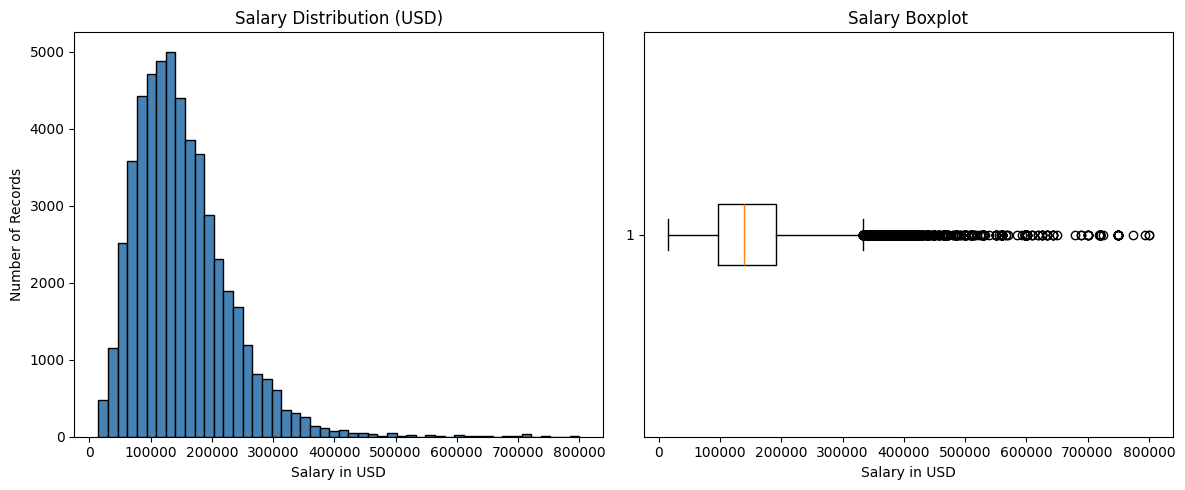

In [33]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].hist(cleaned_df['salary_in_usd'], bins=50, color='steelblue', edgecolor='black')
axes[0].set_title('Salary Distribution (USD)')
axes[0].set_xlabel('Salary in USD')
axes[0].set_ylabel('Number of Records')

axes[1].boxplot(cleaned_df['salary_in_usd'], vert=False)
axes[1].set_title('Salary Boxplot')
axes[1].set_xlabel('Salary in USD')

plt.tight_layout()
plt.show()